# Telco Customer Churn: Exploratory Data Analysis
CM2604 Machine Learning, Coursework Part 01, Task 1

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style = 'whitegrid')
RANDOM_STATE = 42
DATA_PATH = '../data/WA_Fn-UseC_-Telco-Customer-Churn.csv'

## 2. Load the data

In [2]:
# loading the dataset and looking at the shape, first and last few rows, column headings
df = pd.read_csv(DATA_PATH)
print(df.shape)
display(df.head())
display(df.tail())
display(df.columns.tolist())

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [3]:
df.info() 

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 3. Data quality checks

In [4]:
# handling missing and duplicate values
print('Missing values:',df.isna().sum().sum())
print('Duplicate rows:',df.duplicated().sum())
# checking whether there's duplicate IDs since it is the unique value of every row
print('Duplicate IDs:', df.customerID.duplicated().sum())

Missing values: 0
Duplicate rows: 0
Duplicate IDs: 0


`TotalCharges` is read as text. Find out why.

In [5]:
# converting total charges from str to numeric
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df[df['TotalCharges'].isna()][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [6]:
# replacing missing values with 0
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# transferring customerID to the index
if 'customerID' in df.columns:
    df = df.set_index('customerID')

# summary statistics
df.describe().round(1)

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.0,7043.0,7043.0,7043.0
mean,0.2,32.4,64.8,2279.7
std,0.4,24.6,30.1,2266.8
min,0.0,0.0,18.2,0.0
25%,0.0,9.0,35.5,398.6
50%,0.0,29.0,70.4,1394.6
75%,0.0,55.0,89.8,3786.6
max,1.0,72.0,118.8,8684.8


## 4. Target variable

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.5
Yes    26.5
Name: count, dtype: float64


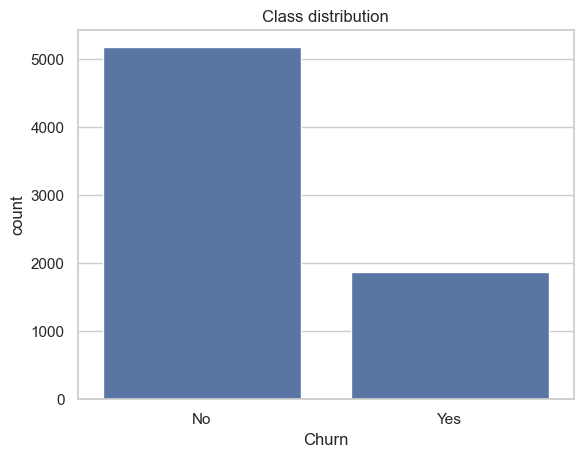

In [7]:
# target split between the two classes yes and no
counts = df['Churn'].value_counts()
print(counts)
print((counts / len(df) * 100).round(1))
sns.countplot(data=df, x='Churn')
plt.title('Class distribution')
plt.show()

**Insight:** the classes are imbalanced (about 26.5% churn), so accuracy alone is not a reliable metric.

## 5. Numerical features

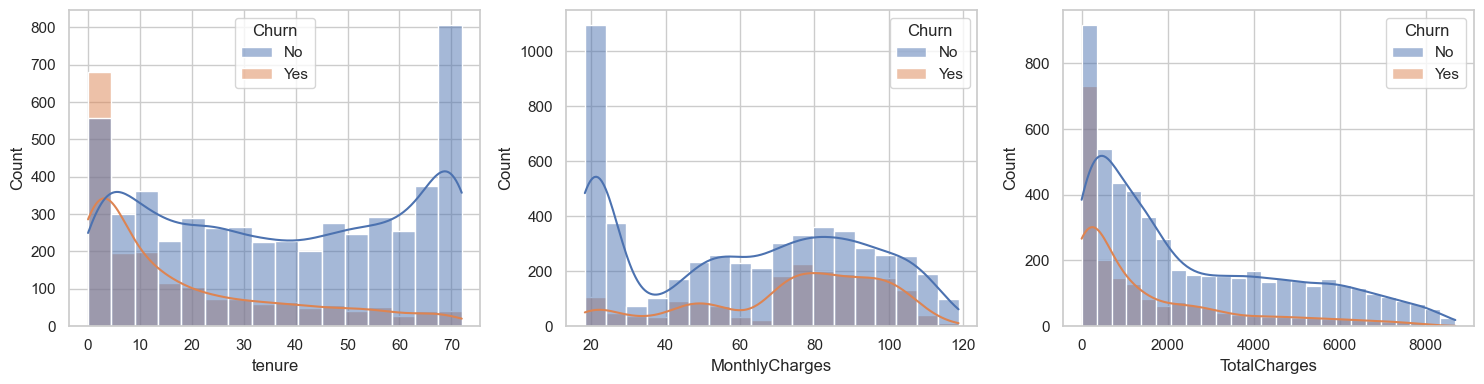

In [8]:
# Plots a histogram of tenure, monthly charges and total charges, coloured by churn, to compare how churners and non-churners differ on each numeric feature.
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(data=df, x=col, hue='Churn', kde=True, ax=ax)
plt.tight_layout()
plt.show()

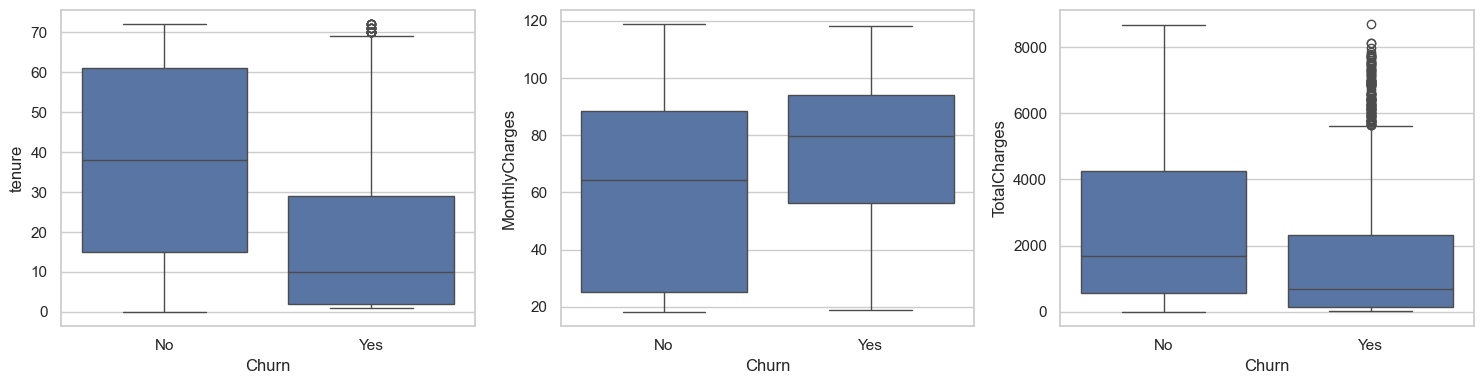

In [9]:
# Boxplots of the numeric features by churn, to compare medians, spread and outliers between churners and non-churners.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x='Churn', y=col, ax=ax)
plt.tight_layout()
plt.show()

## 6. Categorical features vs churn

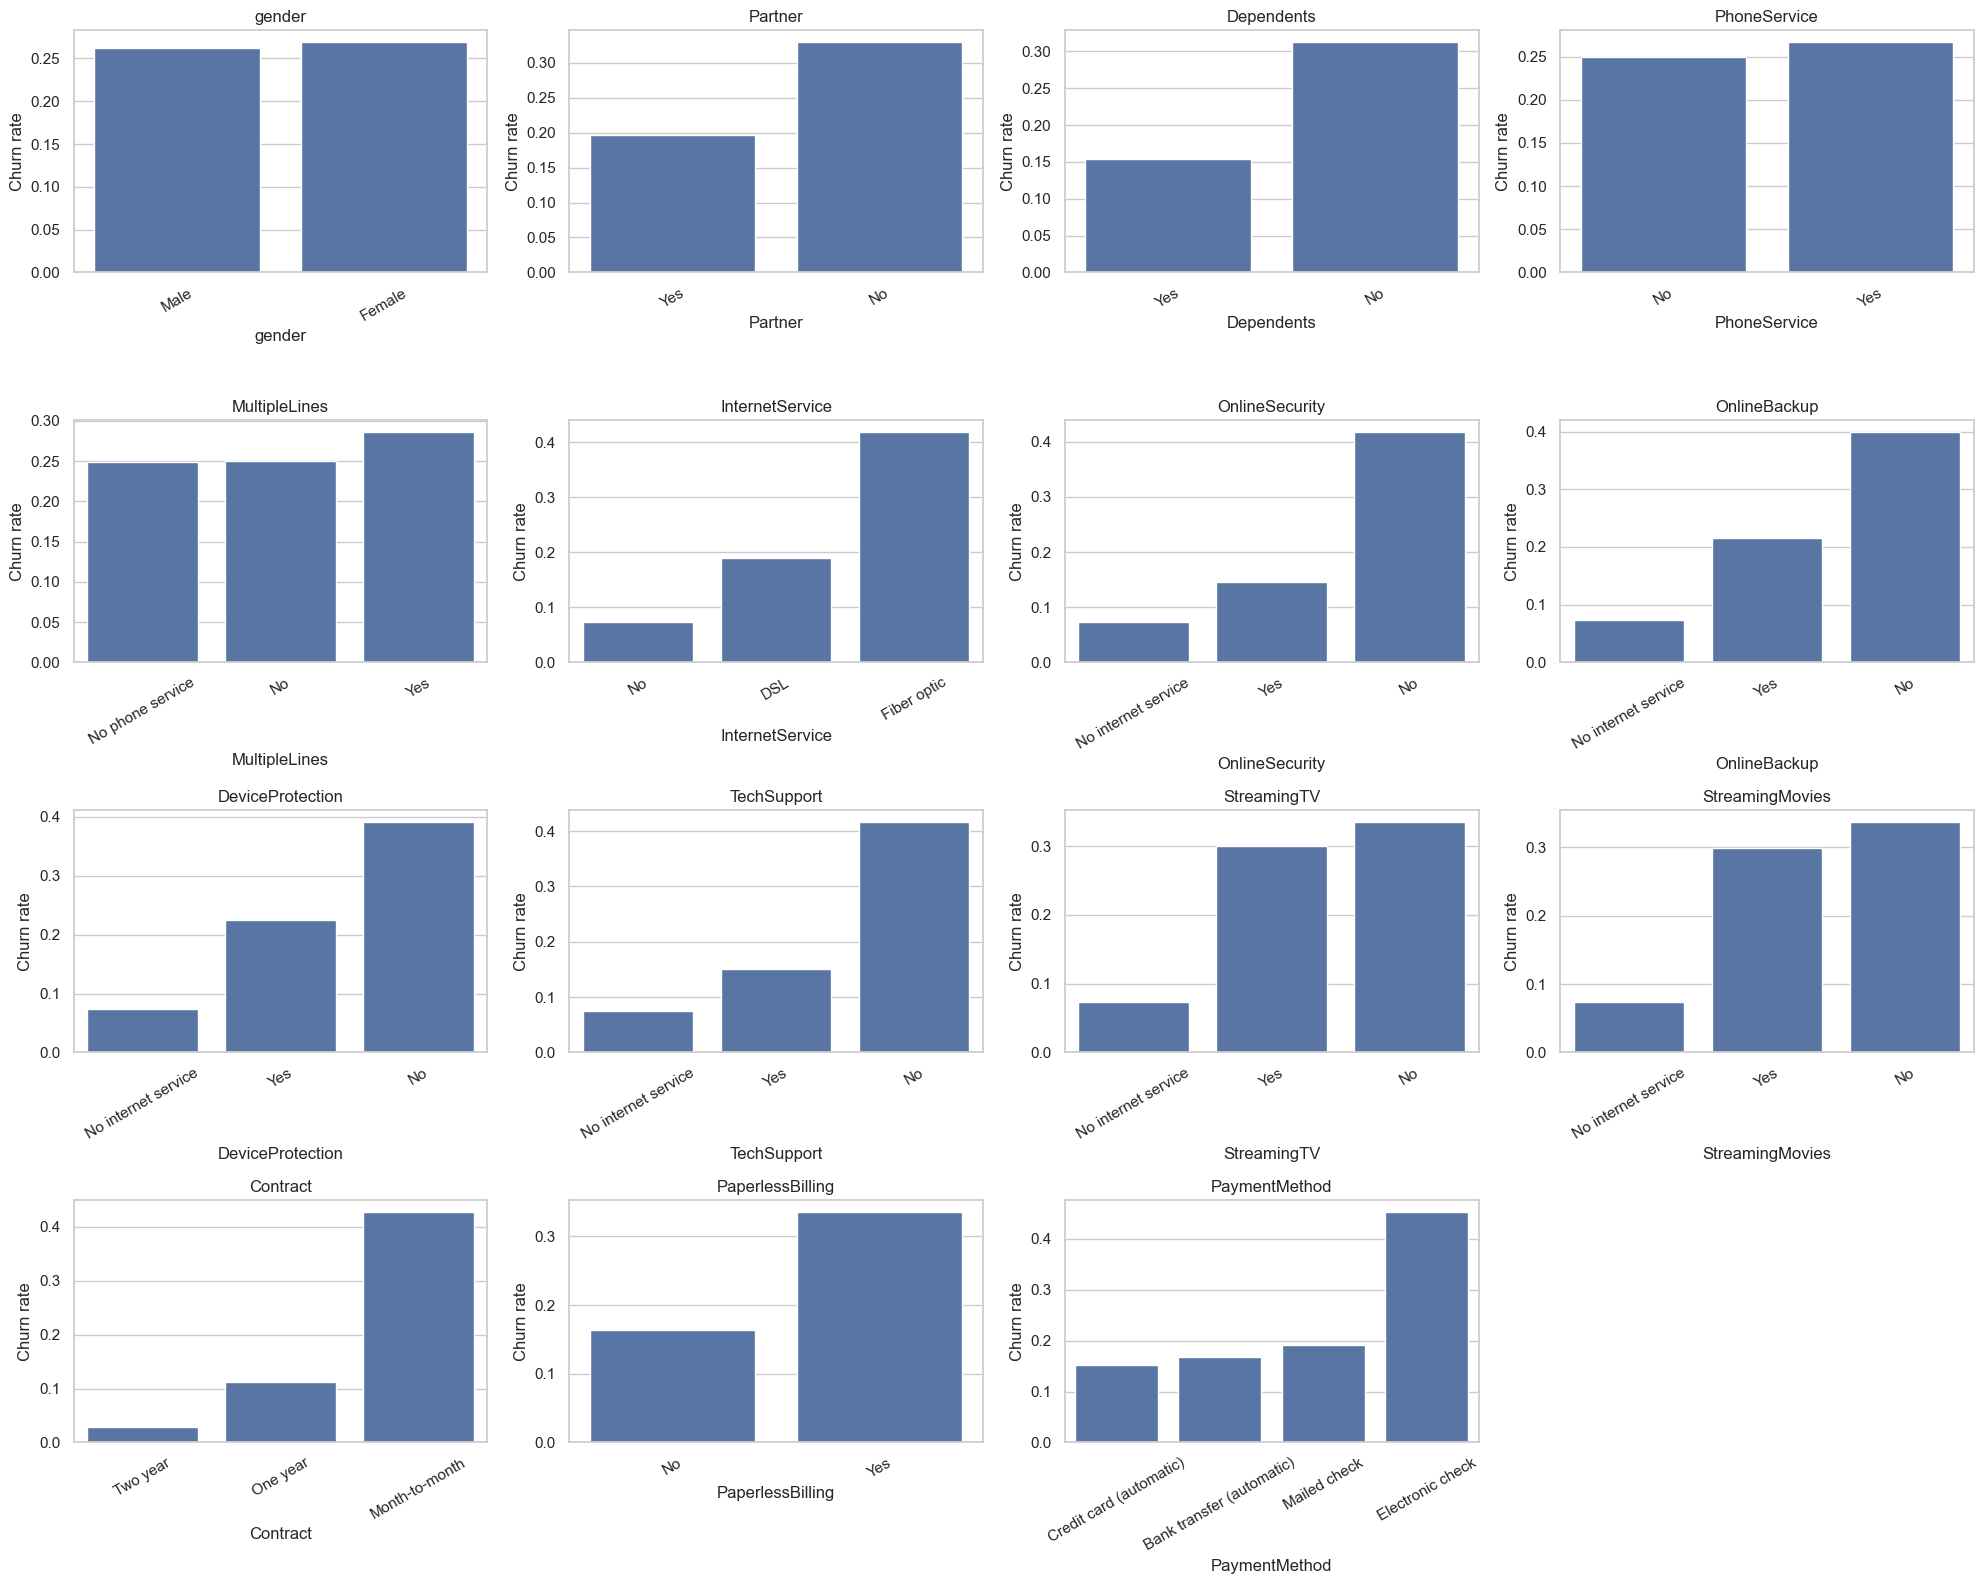

In [10]:
# Bar charts of the churn rate for each categorical feature, to show which categories have the highest and lowest churn.
cat_cols = [c for c in df.select_dtypes(exclude='number').columns if c != 'Churn']
df['ChurnFlag'] = (df['Churn'] == 'Yes').astype(int)

fig, axes = plt.subplots(4, 4, figsize=(20, 16))
for ax, col in zip(axes.ravel(), cat_cols):
    rate = df.groupby(col)['ChurnFlag'].mean().sort_values()
    sns.barplot(x=rate.index, y=rate.values, ax=ax)
    ax.set_title(col)
    ax.set_ylabel('Churn rate')
    ax.tick_params(axis='x', rotation=30)
for ax in axes.ravel()[len(cat_cols):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

## 7. Churn rate by tenure

In [11]:
# Groups customers into tenure bands and shows the churn rate and customer count for each band
df['tenure_band'] = pd.cut(df['tenure'], [-1, 6, 12, 24, 48, 72])
df.groupby('tenure_band', observed=True)['ChurnFlag'].agg(['mean', 'size'])

,mean,size
tenure_band,,
"(-1, 6]",0.529372,1481
"(6, 12]",0.358865,705
"(12, 24]",0.287109,1024
"(24, 48]",0.203890,1594
"(48, 72]",0.095132,2239


## 8. Correlations

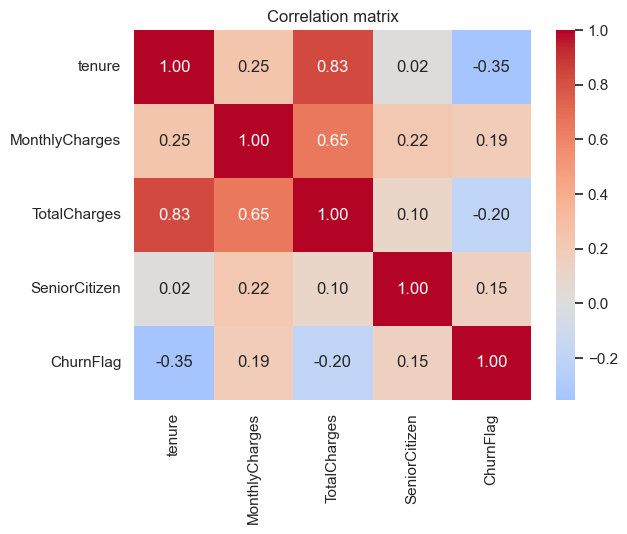

In [12]:
# Heatmap of correlations between the numeric features and churn, showing which relate to churn and which overlap with each other.
corr_cols = num_cols + ['SeniorCitizen', 'ChurnFlag']
sns.heatmap(df[corr_cols].corr(), annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Correlation matrix')
plt.show()

## 9. Insights
Write the findings here, then summarise them in the report.

- The classes are imbalanced: 26.5% of customers churned (1,869 of 7,043), so accuracy alone is misleading and the models need F1, recall and ROC-AUC with a stratified split.
- Contract type is the strongest driver: month-to-month customers churn at 42.7%, against 11.3% for one-year and 2.8% for two-year contracts.
- Churn is highest among new customers: 53% leave within the first 6 months, falling to 9.5% after 4 years, with churners averaging 18 months of tenure against 38 for stayers.
- Fibre optic customers churn at 41.9% (against 19.0% for DSL) and pay the most, at $91.50 a month, and electronic check users churn at 45.3% (against 15–19% for the other payment methods).
- Data quality is good, with no duplicates or missing values apart from 11 blank `TotalCharges` entries (tenure 0), which are filled with 0, and the numeric features need scaling before KNN and Logistic Regression.

# Task 2: Classification Models
Models: K-Nearest Neighbours, Logistic Regression, Random Forest.

Two experimental settings per model: **Setting A** (default parameters) and **Setting B** (hyperparameters tuned with cross-validated grid search).

This part continues from the cleaned `df` produced by the exploratory analysis above.

## 10. Imports for modelling

In [13]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay)

## 11. Prepare the modelling data
The cleaning already done above is reused: `TotalCharges` is numeric and `customerID` is the index, so it is not used as a feature.

The extra columns added during the analysis (`Churn` as text, `ChurnFlag` and `tenure_band`) are removed from the features. Keeping them would leak the target into the model.

In [14]:
# Target: 1 = churned, 0 = stayed (ChurnFlag was created in the exploratory analysis)
y = df['ChurnFlag']

# Features: everything except the target and the helper columns
X = df.drop(columns=['Churn', 'ChurnFlag', 'tenure_band'])

# 'No internet service' and 'No phone service' repeat information already in
# InternetService and PhoneService, so they are merged into 'No'
X = X.replace({'No internet service': 'No', 'No phone service': 'No'})

num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = [c for c in X.columns if c not in num_cols + ['SeniorCitizen']]

print('Features:', X.shape, ' churn rate:', round(y.mean(), 3))
X.head()

Features: (7043, 19)  churn rate: 0.265


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
customerID,,,,,,,,,,,,,,,,,,,
7590-VHVEG,Female,0,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
7795-CFOCW,Male,0,No,No,45,No,No,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65


## 12. Train/test split and preprocessing pipeline

In [15]:
# Stratified split keeps the churn rate (about 26.5%) the same in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print('Train:', X_train.shape, ' churn rate:', round(y_train.mean(), 3))
print('Test: ', X_test.shape, ' churn rate:', round(y_test.mean(), 3))

Train: (5634, 19)  churn rate: 0.265
Test:  (1409, 19)  churn rate: 0.265


The preprocessing is placed **inside the pipeline**, so the scaler and encoder are fitted on the training data only. This avoids data leakage from the test set.

- Numeric features are standardised (z-score). KNN and Logistic Regression need this, because KNN uses distances and Logistic Regression is sensitive to feature scale. It is harmless for Random Forest, and using the same preprocessing keeps the comparison fair.
- Categorical features are one-hot encoded.

In [16]:
def make_preprocessor():
    return ColumnTransformer([
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore'), cat_cols),
    ], remainder='passthrough')  # SeniorCitizen is already 0/1

def make_pipeline(model):
    return Pipeline([('prep', make_preprocessor()), ('model', model)])

## 13. Evaluation helper
Accuracy alone is misleading here, because 73.5% of customers stay. Each model is also scored with precision, recall, F1 and ROC-AUC on the held-out test set.

In [17]:
def evaluate(name, setting, fitted_model):
    pred = fitted_model.predict(X_test)
    proba = fitted_model.predict_proba(X_test)[:, 1]
    return {
        'Model': name, 'Setting': setting,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, proba),
    }

models = {
    'KNN': KNeighborsClassifier(),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(random_state=RANDOM_STATE),
}

## 14. Setting A: default hyperparameters

In [18]:
results = []
for name, model in models.items():
    pipe = make_pipeline(model)
    pipe.fit(X_train, y_train)
    results.append(evaluate(name, 'A: default', pipe))

pd.DataFrame(results).round(3)

,Model,Setting,Accuracy,Precision,Recall,F1,ROC-AUC
0,KNN,A: default,0.769,0.566,0.559,0.563,0.792
1,Logistic Regression,A: default,0.804,0.654,0.556,0.601,0.842
2,Random Forest,A: default,0.784,0.616,0.497,0.550,0.826


## 15. Setting B: hyperparameter tuning
Grid search with stratified 5-fold cross-validation on the **training set only**. The scoring metric is **F1**, because accuracy ignores the minority (churn) class.

| Model | Hyperparameters searched |
|---|---|
| KNN | `n_neighbors`, `weights`, distance `metric` |
| Logistic Regression | regularisation strength `C`, `class_weight` |
| Random Forest | `n_estimators`, `max_depth`, `min_samples_leaf`, `class_weight` |

In [19]:
param_grids = {
    'KNN': {
        'model__n_neighbors': [3, 5, 7, 9, 11, 15, 21, 31],
        'model__weights': ['uniform', 'distance'],
        'model__metric': ['euclidean', 'manhattan'],
    },
    'Logistic Regression': {
        'model__C': [0.01, 0.1, 1, 10, 100],
        'model__class_weight': [None, 'balanced'],
    },
    'Random Forest': {
        'model__n_estimators': [100, 200],
        'model__max_depth': [5, 10, None],
        'model__min_samples_leaf': [1, 5],
        'model__class_weight': [None, 'balanced'],
    },
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
tuned = {}
for name, model in models.items():
    search = GridSearchCV(make_pipeline(model), param_grids[name], scoring='f1', cv=cv)
    search.fit(X_train, y_train)
    tuned[name] = search
    print(f'{name}: best CV F1 = {search.best_score_:.3f}')
    print('   best params:', {k.replace('model__', ''): v for k, v in search.best_params_.items()})

KNN: best CV F1 = 0.604
   best params: {'metric': 'manhattan', 'n_neighbors': 31, 'weights': 'uniform'}


Logistic Regression: best CV F1 = 0.631
   best params: {'C': 0.01, 'class_weight': 'balanced'}


Random Forest: best CV F1 = 0.636
   best params: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 200}


## 16. Comparison of both settings (test set)

In [20]:
for name, search in tuned.items():
    results.append(evaluate(name, 'B: tuned', search.best_estimator_))

results_df = pd.DataFrame(results).sort_values(['Model', 'Setting']).reset_index(drop=True)
results_df.round(3)

,Model,Setting,Accuracy,Precision,Recall,F1,ROC-AUC
0,KNN,A: default,0.769,0.566,0.559,0.563,0.792
1,KNN,B: tuned,0.786,0.602,0.575,0.588,0.832
2,Logistic Regression,A: default,0.804,0.654,0.556,0.601,0.842
3,Logistic Regression,B: tuned,0.741,0.508,0.778,0.615,0.837
4,Random Forest,A: default,0.784,0.616,0.497,0.550,0.826
5,Random Forest,B: tuned,0.769,0.546,0.773,0.640,0.845


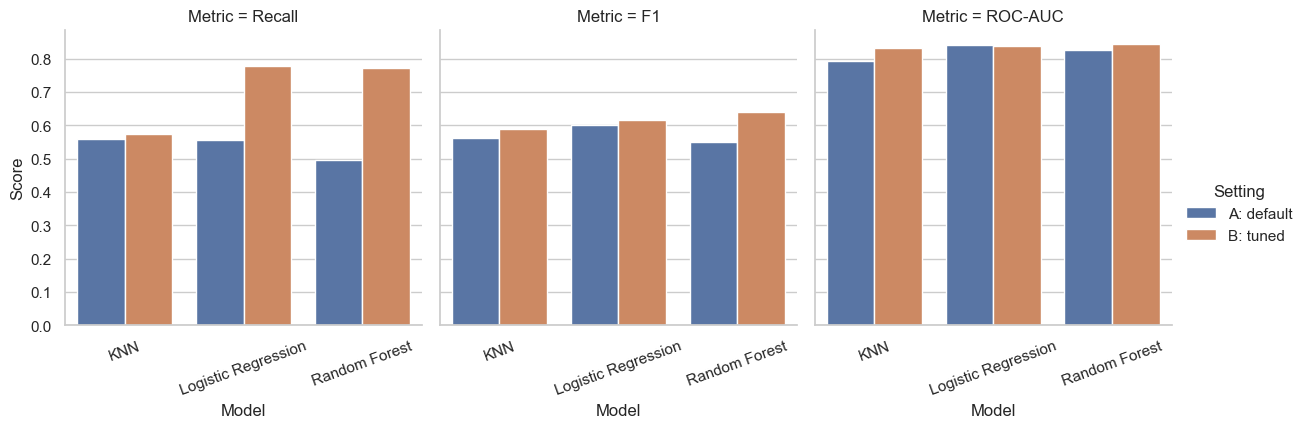

In [21]:
# Recall, F1 and ROC-AUC side by side for both settings
melted = results_df.melt(id_vars=['Model', 'Setting'], value_vars=['Recall', 'F1', 'ROC-AUC'],
                         var_name='Metric', value_name='Score')
g = sns.catplot(data=melted, x='Model', y='Score', hue='Setting', col='Metric',
                kind='bar', height=4, aspect=1)
g.set_xticklabels(rotation=20)
plt.show()

## 17. Confusion matrices and ROC curves (tuned models)

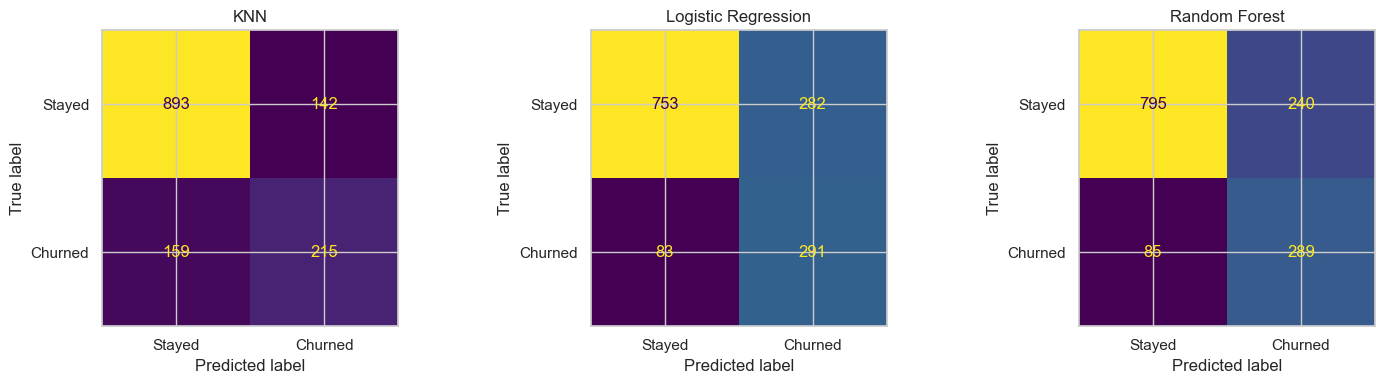

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, search) in zip(axes, tuned.items()):
    ConfusionMatrixDisplay.from_estimator(search.best_estimator_, X_test, y_test,
                                          display_labels=['Stayed', 'Churned'], ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

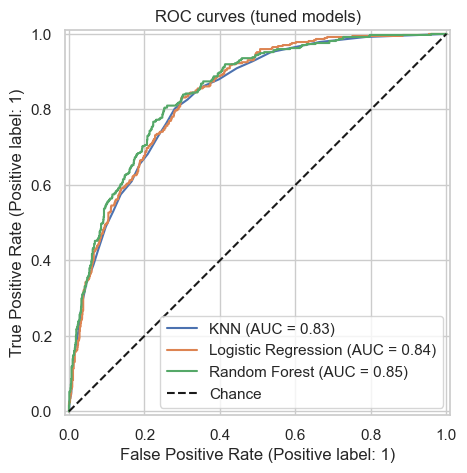

In [23]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, search in tuned.items():
    RocCurveDisplay.from_estimator(search.best_estimator_, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], 'k--', label='Chance')
ax.set_title('ROC curves (tuned models)')
ax.legend()
plt.show()

## 18. Which features matter?

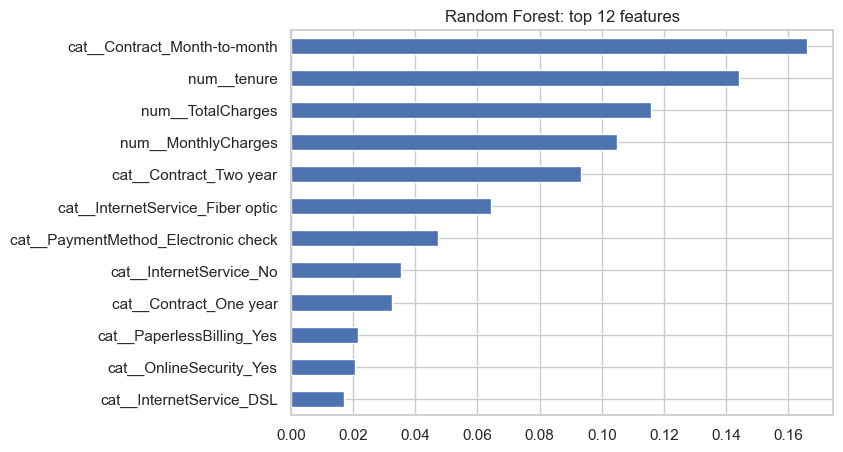

In [24]:
rf = tuned['Random Forest'].best_estimator_
feature_names = rf.named_steps['prep'].get_feature_names_out()
importances = pd.Series(rf.named_steps['model'].feature_importances_, index=feature_names)
importances.sort_values().tail(12).plot(kind='barh', figsize=(7, 5), title='Random Forest: top 12 features')
plt.show()

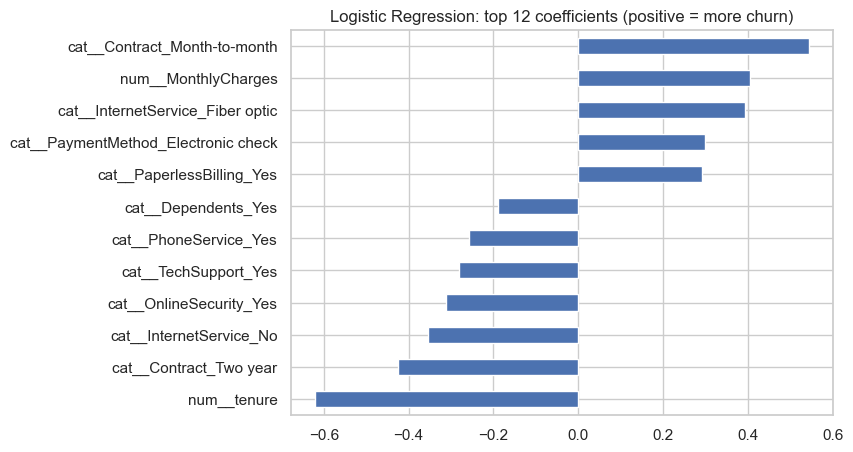

In [25]:
lr = tuned['Logistic Regression'].best_estimator_
coefs = pd.Series(lr.named_steps['model'].coef_[0], index=lr.named_steps['prep'].get_feature_names_out())
top = coefs.reindex(coefs.abs().sort_values().tail(12).index).sort_values()
top.plot(kind='barh', figsize=(7, 5), title='Logistic Regression: top 12 coefficients (positive = more churn)')
plt.show()